# 🏦 Deteksi Penipuan Pembukaan Rekening Bank (Bank Account Fraud)

**Kasus A:** Bank Account Fraud (BAF) - Base Variant (Bulan 0–3)  
**Tujuan:** Mendeteksi pengajuan rekening palsu/penipu sebanyak mungkin dengan syarat nasabah jujur yang keliru dituduh (*False Positive Rate*) dibatasi **maksimal 5%**.  
**Metrik Utama:** True Positive Rate (TPR) pada False Positive Rate (FPR) $\le 5\%$.

---

### 💡 Penjelasan untuk Orang Awam:
1. **Masalah Bisnis:** Bank ingin menangkap penipu saat buka rekening online. Tapi bank tidak boleh sembarangan menuduh nasabah jujur. Kalau nasabah jujur dituduh penipu, mereka akan kecewa dan batal jadi nasabah (*lost customer*), serta menambah beban kerja tim verifikasi bank.
2. **Aturan 5%:** Dari 100 nasabah jujur yang mendaftar, maksimal hanya 5 orang yang boleh tidak sengaja tertandai untuk dicek ulang. Sisanya (95 nasabah jujur) harus langsung lolos.
3. **Target Kita:** Dengan batas toleransi kesalahan 5% tersebut, berapa persen penipu asli yang berhasil ditangkap oleh sistem?


## 1. Import Library
Kita gunakan pustaka standar data science:
* `pandas` & `numpy` untuk mengolah data tabel.
* `lightgbm` sebagai algoritma machine learning (cepat, akurat, standar perbankan).
* `scikit-learn` untuk encoding kategori dan menghitung kurva evaluasi (ROC curve).
* `matplotlib` untuk menggambar grafik kurva evaluasi.
* `joblib` untuk menyimpan dan memuat kembali model.


In [1]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import lightgbm as lgb

# Atur tampilan angka desimal agar rapi
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("Semua library berhasil diimpor!")


Semua library berhasil diimpor!


## 2. Memuat Dataset
Sesuai instruksi, kita menggunakan dataset **Bank Account Fraud (BAF) varian Base** untuk **bulan 0 sampai 3**.
Jika file belum ada di komputer, kode ini otomatis mengunduhnya langsung.


In [2]:
os.makedirs('data', exist_ok=True)
data_path = 'data/Base_month_0_3.csv'

# Download otomatis jika data belum tersedia lokal
if not os.path.exists(data_path):
    print("Mengunduh dataset BAF Base (Bulan 0-3)...")
    url = "https://huggingface.co/datasets/jAEhEEkIM/operationbench-baf-raw/resolve/main/Base.csv"
    chunks = []
    # Baca bertahap (chunking) agar hemat memori
    for chunk in pd.read_csv(url, chunksize=100000):
        filtered = chunk[chunk['month'] <= 3]
        if not filtered.empty:
            chunks.append(filtered)
        if (chunk['month'] > 3).all():
            break
    df = pd.concat(chunks, ignore_index=True)
    df.to_csv(data_path, index=False)
    print("Download selesai dan data berhasil disimpan!")
else:
    print("Membaca data dari file lokal...")
    df = pd.read_csv(data_path)

print(f"Total baris data: {len(df):,} baris")
print(f"Total kolom: {df.shape[1]} kolom")
df.head(3)


Membaca data dari file lokal...


Total baris data: 547,975 baris
Total kolom: 32 kolom


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3000,0.9865,-1,25,40,0.0067,102.4537,AA,1059,...,0,1500.0000,0,INTERNET,16.2248,linux,1,1,0,0
1,0,0.8000,0.6174,-1,89,20,0.0101,-0.8496,AD,1658,...,0,1500.0000,0,INTERNET,3.3639,other,1,1,0,0
2,0,0.8000,0.9967,9,14,40,0.0123,-1.4904,AB,1095,...,0,200.0000,0,INTERNET,22.7306,windows,0,1,0,0


## 3. Eksplorasi Singkat Data (EDA)
Mari kita lihat sebaran data per bulan dan rasio penipu (*fraud*).


In [3]:
print("--- Jumlah Pengajuan per Bulan ---")
print(df['month'].value_counts().sort_index())

print("\n--- Proporsi Label Fraud (0 = Nasabah Jujur, 1 = Penipu) ---")
fraud_counts = df['fraud_bool'].value_counts()
print(f"Nasabah Jujur (0) : {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"Penipu / Fraud (1): {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")


--- Jumlah Pengajuan per Bulan ---
month
0    132440
1    127620
2    136979
3    150936
Name: count, dtype: int64

--- Proporsi Label Fraud (0 = Nasabah Jujur, 1 = Penipu) ---
Nasabah Jujur (0) : 542,687 (99.03%)
Penipu / Fraud (1): 5,288 (0.97%)


## 4. Pembagian Data Latih dan Validasi (*Data Splitting*)

### 📌 Strategi Pembagian: *Temporal Split (Berdasarkan Waktu)*
* **Data Latih (Train):** Bulan 0, 1, dan 2 (total 397.039 pengajuan)
* **Data Validasi (Val):** Bulan 3 (total 150.936 pengajuan)

### ❓ Kenapa Memilih Cara Ini? (Alasan untuk Dosen/Awam)
Di dunia perbankan nyata, kita tidak boleh mengacak data (*random split*). Kenapa?
1. **Mencegah Kebocoran Data (*Data Leakage*):** Jika diacak, model bisa belajar dari masa depan untuk menebak masa lalu.
2. **Pola Penipu Berubah (*Concept Drift*):** Trik penipu bulan ini seringkali berbeda dengan bulan lalu. Dengan melatih model di bulan 0–2 dan mengujinya di bulan 3, kita mensimulasikan kondisi riil bank: model dilatih pakai data riwayat masa lalu untuk menghadapi nasabah baru di masa depan.


In [4]:
train_df = df[df['month'] < 3].copy()
val_df = df[df['month'] == 3].copy()

print(f"Jumlah Data Latih (Bulan 0-2)   : {len(train_df):,} baris ({len(train_df)/len(df)*100:.1f}%)")
print(f"Jumlah Data Validasi (Bulan 3) : {len(val_df):,} baris ({len(val_df)/len(df)*100:.1f}%)")


Jumlah Data Latih (Bulan 0-2)   : 397,039 baris (72.5%)
Jumlah Data Validasi (Bulan 3) : 150,936 baris (27.5%)


## 5. Preprocessing Data (Sederhana & Mudah Dipahami)
Komputer hanya memahami angka. Di data kita, ada 5 kolom berisi teks:
* `payment_type` (metode pembayaran)
* `employment_status` (status pekerjaan)
* `housing_status` (status tempat tinggal)
* `source` (sumber pengajuan, misal INTERNET)
* `device_os` (sistem operasi perangkat, misal windows, linux, mac)

Kita cukup menggunakan **Ordinal Encoding**, yaitu mengubah setiap kategori teks menjadi angka sederhana (0, 1, 2, dst.).
Kolom `month` dan label `fraud_bool` dipisahkan dari fitur pengajuan.


In [5]:
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
feature_cols = [c for c in df.columns if c not in ['fraud_bool', 'month']]

# Ubah teks kategori menjadi angka
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Fit hanya pada data latih, lalu transform kedua data
train_df[categorical_cols] = encoder.fit_transform(train_df[categorical_cols].astype(str))
val_df[categorical_cols] = encoder.transform(val_df[categorical_cols].astype(str))

# Siapkan input (X) dan target (y)
X_train = train_df[feature_cols]
y_train = train_df['fraud_bool']

X_val = val_df[feature_cols]
y_val = val_df['fraud_bool']

print(f"Total fitur yang digunakan: {len(feature_cols)} fitur")
print("Contoh 5 fitur pertama:", feature_cols[:5])


Total fitur yang digunakan: 30 fitur
Contoh 5 fitur pertama: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age']


## 6. Pelatihan Model (LightGBM)

### ❓ Kenapa Memilih LightGBM?
* **Standar Industri FinTech:** Algoritma berbasis *Gradient Boosted Decision Trees* terbukti paling tangguh untuk data tabel transaksi bank.
* **Cepat & Ringan:** Pelatihan 400 ribu data selesai hanya dalam belasan detik di laptop biasa.
* **Kalibrasi Probabilitas Bagus:** Model menghasilkan skor probabilitas yang akurat untuk menentukan batas ambang (*threshold*).


In [6]:
# Inisialisasi model LightGBM dengan parameter yang stabil dan sederhana
model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1
)

print("Memulai pelatihan model LightGBM...")
model.fit(X_train, y_train)
print("Pelatihan selesai!")


Memulai pelatihan model LightGBM...


Pelatihan selesai!


## 7. Evaluasi & Mengunci Batas Eror (FPR $\le$ 5%)

### 🎯 Cara Mencari Batas Eror $\le$ 5%:
1. Model memprediksi **skor probabilitas fraud** (antara 0.0 hingga 1.0) untuk setiap nasabah di data validasi.
2. Kita hitung kurva ROC (*Receiver Operating Characteristic*) untuk melihat seluruh kombinasi FPR dan TPR di setiap kemungkinan threshold.
3. Kita cari **threshold probabilitas** di mana nasabah jujur yang salah dituduh (*FPR*) berada **tepat di bawah atau sama dengan 5%**.
4. Di threshold tersebut, kita hitung persentase penipu yang berhasil tertangkap (**TPR**).


In [7]:
# 1. Dapatkan prediksi probabilitas fraud pada data validasi
val_probs = model.predict_proba(X_val)[:, 1]

# 2. Hitung ROC Curve
fpr, tpr, thresholds = roc_curve(y_val, val_probs)
auc_score = roc_auc_score(y_val, val_probs)

# 3. Cari index di mana FPR <= 5% (0.05)
idx_5pct = np.where(fpr <= 0.05)[0][-1]

best_threshold = float(thresholds[idx_5pct])
final_fpr = float(fpr[idx_5pct])
final_tpr = float(tpr[idx_5pct])

print("=" * 55)
print("           HASIL EVALUASI DATA VALIDASI (BULAN 3)")
print("=" * 55)
print(f"ROC-AUC Score                  : {auc_score:.4f}")
print(f"Batas Ambang (Threshold)       : {best_threshold:.4f}")
print(f"Nasabah Jujur Keliru (FPR)     : {final_fpr * 100:.2f}%  (Syarat: <= 5.0%)")
print(f"Penipu Berhasil Ditangkap (TPR): {final_tpr * 100:.2f}%")
print("=" * 55)


           HASIL EVALUASI DATA VALIDASI (BULAN 3)
ROC-AUC Score                  : 0.9100
Batas Ambang (Threshold)       : 0.0523
Nasabah Jujur Keliru (FPR)     : 4.98%  (Syarat: <= 5.0%)
Penipu Berhasil Ditangkap (TPR): 56.54%


## 8. Visualisasi Kurva ROC & Titik Target Eror 5%
Grafik ini memperlihatkan posisi model kita saat batas kesalahan nasabah jujur dikunci maksimal 5%.


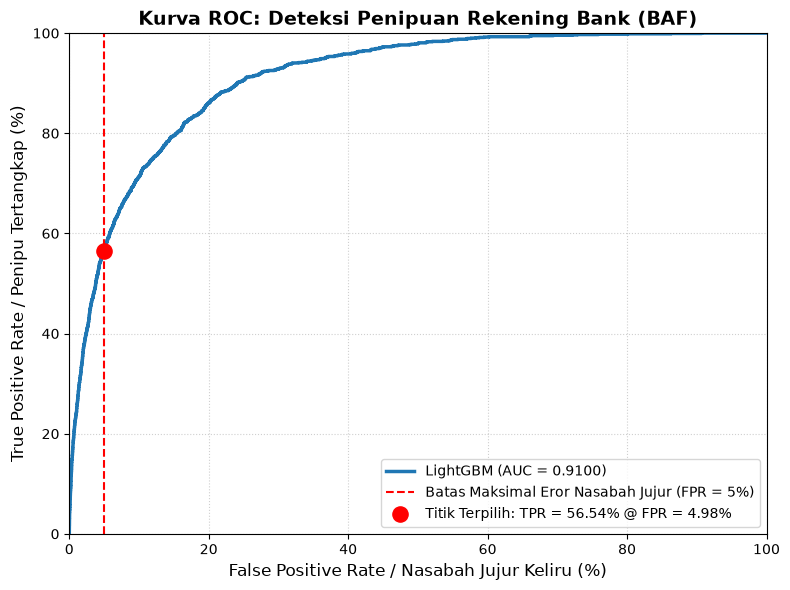

In [8]:
plt.figure(figsize=(8, 6))
plt.plot(fpr * 100, tpr * 100, color='#1f77b4', lw=2.5, label=f'LightGBM (AUC = {auc_score:.4f})')
plt.axvline(x=5.0, color='red', linestyle='--', label='Batas Maksimal Eror Nasabah Jujur (FPR = 5%)')
plt.scatter([final_fpr * 100], [final_tpr * 100], color='red', s=120, zorder=5, 
            label=f'Titik Terpilih: TPR = {final_tpr * 100:.2f}% @ FPR = {final_fpr * 100:.2f}%')

plt.title('Kurva ROC: Deteksi Penipuan Rekening Bank (BAF)', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate / Nasabah Jujur Keliru (%)', fontsize=12)
plt.ylabel('True Positive Rate / Penipu Tertangkap (%)', fontsize=12)
plt.xlim([0, 100])
plt.ylim([0, 100])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


## 9. Menyimpan File Model
Sesuai instruksi tugas, model harus disimpan agar bisa dimuat ulang.
Kita simpan satu paket lengkap (`fraud_detector_lgbm.joblib`) yang berisi:
* Model LightGBM yang sudah dilatih
* Encoder kategori (agar data input baru otomatis di-encode)
* Daftar kolom fitur
* Threshold optimal (FPR $\le$ 5%)
* Metrik evaluasi tersimpan


In [9]:
os.makedirs('model', exist_ok=True)
model_path = 'model/fraud_detector_lgbm.joblib'

model_bundle = {
    'model': model,
    'encoder': encoder,
    'categorical_cols': categorical_cols,
    'feature_cols': feature_cols,
    'threshold': best_threshold,
    'metrics': {
        'auc': auc_score,
        'fpr_at_5pct': final_fpr,
        'tpr_at_5pct': final_tpr
    }
}

joblib.dump(model_bundle, model_path)
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model berhasil disimpan di: {model_path}")
print(f"Ukuran file: {file_size_mb:.2f} MB (sangat aman di bawah batas GitHub 100MB)")


Model berhasil disimpan di: model/fraud_detector_lgbm.joblib
Ukuran file: 1.00 MB (sangat aman di bawah batas GitHub 100MB)


## 10. Pengujian Muat Ulang Model (*Reload & Inference Verification*)
Di tahap ini, kita buktikan bahwa file model yang disimpan bisa dimuat ulang dan langsung digunakan untuk memprediksi pengajuan nasabah baru.


In [10]:
# 1. Muat ulang model dari disk
loaded_bundle = joblib.load(model_path)
print("Model berhasil dimuat kembali!")
print(f"Threshold operasional tersimpan: {loaded_bundle['threshold']:.4f}")

# 2. Fungsi sederhana untuk memprediksi nasabah baru
def predict_application(application_data, bundle):
    """
    Fungsi prediksi untuk orang awam:
    Menerima data pengajuan baru, mengembalikan skor risiko dan keputusan.
    """
    input_df = application_data[bundle['feature_cols']].copy()
    # Encode kolom kategori teks
    input_df[bundle['categorical_cols']] = bundle['encoder'].transform(
        input_df[bundle['categorical_cols']].astype(str)
    )
    # Hitung probabilitas fraud
    fraud_prob = bundle['model'].predict_proba(input_df)[:, 1][0]
    
    is_fraud = fraud_prob >= bundle['threshold']
    status = "🚨 PERIKSA MANUAL (Indikasi Fraud)" if is_fraud else "✅ LOLOS OTOMATIS (Nasabah Normal)"
    return fraud_prob, status

# 3. Uji coba pada 2 contoh pengajuan dari data validasi
sample_honest = val_df[val_df['fraud_bool'] == 0].iloc[[0]]
sample_fraud = val_df[val_df['fraud_bool'] == 1].iloc[[0]]

prob_honest, status_honest = predict_application(sample_honest, loaded_bundle)
prob_fraud, status_fraud = predict_application(sample_fraud, loaded_bundle)

print("\n--- Hasil Uji Coba Pengajuan 1 (Aslinya Nasabah Jujur) ---")
print(f"Skor Risiko Fraud : {prob_honest * 100:.2f}%")
print(f"Keputusan Sistem  : {status_honest}")

print("\n--- Hasil Uji Coba Pengajuan 2 (Aslinya Penipu) ---")
print(f"Skor Risiko Fraud : {prob_fraud * 100:.2f}%")
print(f"Keputusan Sistem  : {status_fraud}")


Model berhasil dimuat kembali!
Threshold operasional tersimpan: 0.0523

--- Hasil Uji Coba Pengajuan 1 (Aslinya Nasabah Jujur) ---
Skor Risiko Fraud : 0.13%
Keputusan Sistem  : ✅ LOLOS OTOMATIS (Nasabah Normal)

--- Hasil Uji Coba Pengajuan 2 (Aslinya Penipu) ---
Skor Risiko Fraud : 11.51%
Keputusan Sistem  : 🚨 PERIKSA MANUAL (Indikasi Fraud)
